# Second-Order Linear ODEs: Damped SHM and RK4

**References:** `Notes/lec9.pdf`, `Notes/lec10.pdf`, `Notes/SHM_rk4.ipynb` (Professor code), `n/Simple Harmonic Ocilator.ipynb`, `Notes/Quiz2/08_ODE_Systems_and_Nonlinear_Solvers.ipynb`

## Concept & Formulas
Damped harmonic oscillator equation: $m\frac{d^2x}{dt^2} + \gamma\frac{dx}{dt} + kx = 0$.

- **Convert to 1st-Order System:** Let $y_0 = x$ and $y_1 = v = \frac{dx}{dt}$, so:
  $$\frac{dy_0}{dt} = y_1, \qquad \frac{dy_1}{dt} = -\frac{\gamma}{m}y_1 - \frac{k}{m}y_0$$
- **Three Damping Regimes** (let $\omega_0 = \sqrt{k/m}$ and $b = \gamma/(2m)$):
  1. Underdamped ($b < \omega_0$): decays with oscillations.
  2. Critically damped ($b = \omega_0$): fastest decay without oscillation.
  3. Overdamped ($b > \omega_0$): slow monotonic decay (mass term $m\ddot{x}$ becomes small over long timescales $\tau = \gamma/k$).
- **RK4 Method:** Evaluates 4 slopes $k_1, k_2, k_3, k_4$ per step and updates $y_{n+1} = y_n + \frac{\Delta t}{6}(k_1 + 2k_2 + 2k_3 + k_4)$ — accuracy $O(\Delta t^4)$.
- **Limitations of Simple Euler on SHM:** Simple Euler adds artificial energy every step, so an undamped oscillator ($\gamma=0$) spirals outward instead of keeping constant amplitude. RK4 or Euler-Cromer (semi-implicit Euler) avoids this blowup.

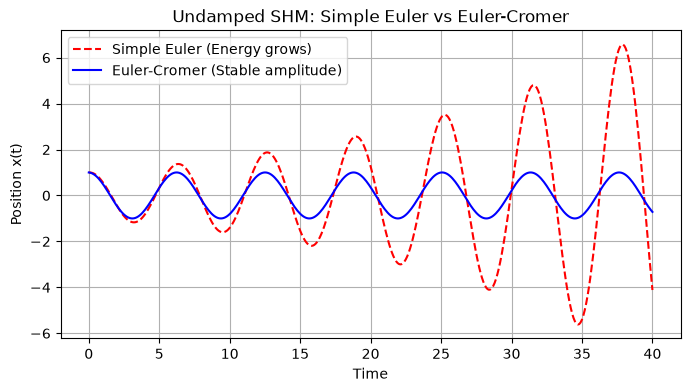

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Undamped SHM (gamma = 0): Simple Euler blows up vs Euler-Cromer stays bounded
k, m = 1.0, 1.0
dt = 0.1
t = np.arange(0, 40 + dt, dt)
n = len(t)

x_eu = np.zeros(n); v_eu = np.zeros(n)
x_ec = np.zeros(n); v_ec = np.zeros(n)
x_eu[0], v_eu[0] = 1.0, 0.0
x_ec[0], v_ec[0] = 1.0, 0.0

for i in range(n - 1):
    # Simple Euler (uses old v to update x)
    x_eu[i + 1] = x_eu[i] + v_eu[i] * dt
    v_eu[i + 1] = v_eu[i] - (k / m) * x_eu[i] * dt

    # Euler-Cromer (updates v first, then uses NEW v for x)
    v_ec[i + 1] = v_ec[i] - (k / m) * x_ec[i] * dt
    x_ec[i + 1] = x_ec[i] + v_ec[i + 1] * dt

plt.figure(figsize=(8, 4))
plt.plot(t, x_eu, 'r--', label='Simple Euler (Energy grows)')
plt.plot(t, x_ec, 'b-', label='Euler-Cromer (Stable amplitude)')
plt.xlabel('Time')
plt.ylabel('Position x(t)')
plt.title('Undamped SHM: Simple Euler vs Euler-Cromer')
plt.legend()
plt.grid(True)
plt.show()

---
## Professor's Code (`Notes/SHM_rk4.ipynb`)
Exact RK4 implementation from the professor's notebook for damped SHM.

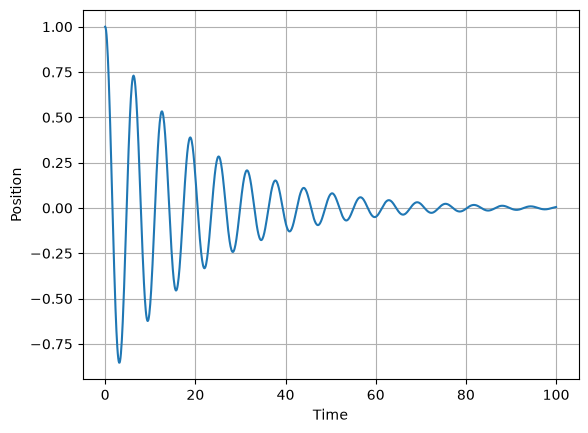

In [2]:
import numpy as np
import matplotlib.pyplot as plt

k = 1                 # spring constant
m = 1                 # mass
gamma = 0.1           # damping coefficient
t_end = 100           # final time
dt = 0.1               # time step
y0 = np.array([1, 0])  # initial conditions: position, velocity

t = np.arange(0, t_end + dt, dt)  # time vector, including t_end
n = len(t) 

y = np.zeros((2, n))              # solution matrix: row 0 = position, row 1 = velocity
y[:, 0] = y0                      # set initial conditions

for i in range(n - 1):
    k1 = np.array([
        y[1, i],
        -(gamma / m * y[1, i] + k / m * y[0, i])
    ])

    k2 = np.array([
        y[1, i] + 0.5 * dt * k1[1],
        -k / m * (y[0, i] + 0.5 * dt * k1[0])
        - gamma / m * (y[1, i] + 0.5 * dt * k1[1])
    ])

    k3 = np.array([
        y[1, i] + 0.5 * dt * k2[1],
        -k / m * (y[0, i] + 0.5 * dt * k2[0])
        - gamma / m * (y[1, i] + 0.5 * dt * k2[1])
    ])

    k4 = np.array([
        y[1, i] + dt * k3[1],
        -k / m * (y[0, i] + dt * k3[0])
        - gamma / m * (y[1, i] + dt * k3[1])
    ])

    # update solution
    y[:, i + 1] = y[:, i] + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6

plt.plot(t, y[0, :])
plt.xlabel("Time")
plt.ylabel("Position")
plt.grid(True)
plt.show()

---
## Class Notebook Code (`n/Simple Harmonic Ocilator.ipynb`)
Simple Euler and Improved Euler loops for SHM taught in class.

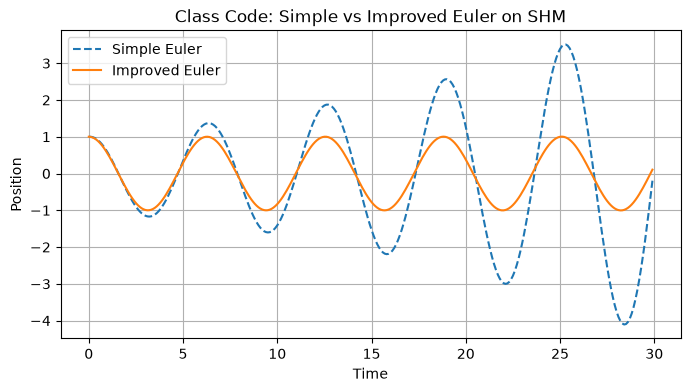

In [3]:
# From n/Simple Harmonic Ocilator.ipynb
def simple_euler_shm(x0, v0, k, m, dt, t_total):
    t = np.arange(0, t_total, dt)
    x = np.zeros(len(t))
    v = np.zeros(len(t))
    x[0], v[0] = x0, v0
    for i in range(len(t) - 1):
        x[i + 1] = x[i] + v[i] * dt
        v[i + 1] = v[i] - (k / m) * x[i] * dt
    return t, x, v

def improved_euler_shm(x0, v0, k, m, dt, t_total):
    t = np.arange(0, t_total, dt)
    x = np.zeros(len(t))
    v = np.zeros(len(t))
    x[0], v[0] = x0, v0
    for i in range(len(t) - 1):
        x_mid = x[i] + v[i] * dt / 2
        v_mid = v[i] - (k / m) * x[i] * dt / 2
        x[i + 1] = x[i] + v_mid * dt
        v[i + 1] = v[i] - (k / m) * x_mid * dt
    return t, x, v

t1, x1, v1 = simple_euler_shm(1, 0, 1, 1, 0.1, 30)
t2, x2, v2 = improved_euler_shm(1, 0, 1, 1, 0.1, 30)

plt.figure(figsize=(8, 4))
plt.plot(t1, x1, '--', label='Simple Euler')
plt.plot(t2, x2, '-', label='Improved Euler')
plt.xlabel('Time')
plt.ylabel('Position')
plt.title('Class Code: Simple vs Improved Euler on SHM')
plt.legend()
plt.grid(True)
plt.show()